# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Diyanti Pratiwi
- **Email:** ds284b6x0476@student.devacademy.id
- **ID Dicoding:** ds284b6x0476

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Pertanyaan 1:** "Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara pengguna casual dan registered pada hari kerja dibandingkan akhir pekan/hari libur sepanjang periode 2011–2012, serta pada jam berapa puncak lonjakan permintaan terjadi?"

Keterangan:
- Specific: Fokus membandingkan pola penyewaan dua segmen pengguna (casual vs registered) berdasarkan jenis hari (hari kerja vs akhir pekan/libur) dan jam operasional.
- Measurable: Menggunakan metrik angka konkret berupa rata-rata jumlah penyewaan per jam dan titik jam puncak (peak hours).
- Action-Oriented: Mengetahui jam puncak masing-masing segmen memudahkan tim operasional menentukan jadwal distribusi ulang (rebalancing) armada serta waktu yang tepat untuk promo konversi member.
- Relevant: Pola jam sibuk dan perilaku segmen pengguna berkaitan langsung dengan ketersediaan sepeda dan optimalisasi pendapatan layanan bike sharing.
- Time-bound: Dibatasi secara jelas pada rentang data periode 2011–2012.

**Pertanyaan 2:** "Berapa rata-rata jumlah penyewaan sepeda harian dan persentase penurunannya pada setiap kondisi cuaca serta pergantian musim sepanjang tahun 2011–2012?"

Keterangan:
- Specific: Fokus menganalisis pengaruh kondisi cuaca dan musim terhadap volume penyewaan sepeda harian.
- Measurable: Mengukur metrik rata-rata jumlah penyewaan harian dan besar persentase penurunannya di tiap kategori cuaca maupun musim.
- Action-Oriented: Periode cuaca atau musim dengan tingkat penurunan permintaan paling tajam bisa langsung dijadikan jadwal perawatan rutin armada (preventive maintenance) tanpa mengorbankan potensi pendapatan di hari ramai.
- Relevant: Faktor cuaca dan musim berdampak langsung pada permintaan pelanggan dan efisiensi operasional armada di lapangan.
- Time-bound: Dibatasi pada periode waktu sepanjang tahun 2011–2012.


## Import Semua Packages/Library yang Digunakan

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

## Data Wrangling

### Gathering Data

#### Load `day.csv` dan `hour.csv`

In [17]:
day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')

print(f'Dimensi day_df : {day_df.shape[0]} baris, {day_df.shape[1]} kolom')
print(f'Dimensi hour_df: {hour_df.shape[0]} baris, {hour_df.shape[1]} kolom')

print('\n--- 3 Baris Pertama day_df ---')
print(day_df.head(3))
print('\n--- 3 Baris Pertama hour_df ---')
print(hour_df.head(3))

Dimensi day_df : 731 baris, 16 kolom
Dimensi hour_df: 17379 baris, 17 kolom

--- 3 Baris Pertama day_df ---
   instant      dteday  season  yr  mnth  holiday  weekday  workingday  weathersit      temp     atemp       hum  windspeed  casual  registered   cnt
0        1  2011-01-01       1   0     1        0        6           0           2  0.344167  0.363625  0.805833   0.160446     331         654   985
1        2  2011-01-02       1   0     1        0        0           0           2  0.363478  0.353739  0.696087   0.248539     131         670   801
2        3  2011-01-03       1   0     1        0        1           1           1  0.196364  0.189405  0.437273   0.248309     120        1229  1349

--- 3 Baris Pertama hour_df ---
   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  weathersit  temp   atemp   hum  windspeed  casual  registered  cnt
0        1  2011-01-01       1   0     1   0        0        6           0           1  0.24  0.2879  0.81        0.

**Insight:** (Opsional)
- Dataset `day.csv` berisi **731 baris** catatan penyewaan sepeda agregasi harian selama 2 tahun penuh (1 Januari 2011 – 31 Desember 2012, mencakup tahun kabisat 2012 yang memiliki 366 hari).
- Dataset `hour.csv` berisi **17.379 baris** catatan agregasi per jam dengan struktur kolom yang identik, ditambah kolom `hr` (jam 0 sampai 23).

### Assessing Data

#### Identifying Data Quality Problems

In [18]:
print('=== INFO DAY_DF ===')
day_df.info()
print('\n=== INFO HOUR_DF ===')
hour_df.info()

print('\nMissing value day_df :', day_df.isna().sum().sum())
print('Missing value hour_df:', hour_df.isna().sum().sum())
print('Duplicate day_df     :', day_df.duplicated().sum())
print('Duplicate hour_df    :', hour_df.duplicated().sum())

print('=== STATISTIK DESKRIPTIF DAY_DF ===')
print(day_df.describe().round(3))
print('\n=== STATISTIK DESKRIPTIF HOUR_DF ===')
print(hour_df.describe().round(3))

# Cek konsistensi penjumlahan casual + registered == cnt
print('\nSelisih casual + registered != cnt (day) :', (day_df['casual'] + day_df['registered'] != day_df['cnt']).sum())
print('Selisih casual + registered != cnt (hour):', (hour_df['casual'] + hour_df['registered'] != hour_df['cnt']).sum())

# Cek nilai tidak valid secara fisik (kelembapan == 0)
print('\nData dengan hum == 0 di day_df:')
print(day_df[day_df['hum'] == 0][['instant', 'dteday', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']])
print('Jumlah baris dengan hum == 0 di hour_df:', (hour_df['hum'] == 0).sum())
print(hour_df[hour_df['hum'] == 0][['dteday', 'hr', 'weathersit', 'hum']])

def check_outliers_iqr(df, cols):
    summary = []
    for col in cols:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        count = ((df[col] < lower) | (df[col] > upper)).sum()
        summary.append({'Kolom': col, 'Batas Bawah': round(lower, 3), 'Batas Atas': round(upper, 3), 'Jumlah Outlier': count})
    return pd.DataFrame(summary)

day_iqr_df = check_outliers_iqr(day_df, ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt'])
hour_iqr_df = check_outliers_iqr(hour_df, ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt'])

print('Outlier IQR pada day_df:')
print(day_iqr_df)
print('\nOutlier IQR pada hour_df:')
print(hour_iqr_df)

# Bukti konteks outlier pada hour_df menggunakan batas atas IQR dinamis
upper_casual = hour_iqr_df.loc[hour_iqr_df['Kolom'] == 'casual', 'Batas Atas'].values[0]
upper_registered = hour_iqr_df.loc[hour_iqr_df['Kolom'] == 'registered', 'Batas Atas'].values[0]

out_cas = hour_df[hour_df['casual'] > upper_casual]
out_reg = hour_df[hour_df['registered'] > upper_registered]
print(f"Batas atas IQR casual ({upper_casual}) -> Outlier di Weekend/Holiday : {(out_cas['workingday'] == 0).mean()*100:.2f}%")
print(f"Batas atas IQR registered ({upper_registered}) -> Outlier di Working Day : {(out_reg['workingday'] == 1).mean()*100:.2f}%")
print("Top jam outlier registered         :", out_reg['hr'].value_counts().head(3).to_dict())



=== INFO DAY_DF ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

=== INFO HOUR_DF ===
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
D

**Steps to Take:**
**Steps to Take:**
1. **Perbaikan Tipe Data (`dteday`):** Mengubah kolom `dteday` pada `day_df` dan `hour_df` dari tipe `object` (string) menjadi `datetime64`.
2. **Penanganan *Invalid Value* (`hum == 0`):** Pada tanggal `2011-03-10`, tercatat nilai kelembapan `0.0` pada seluruh 22 jam pengamatan padahal kondisi cuaca (`weathersit`) adalah `3` (hujan ringan/salju). Secara meteorologis mustahil terjadi hujan pada kelembapan 0% (indikasi gangguan sensor), sehingga nilai `0.0` akan diimputasi menggunakan median kelembapan pada kondisi cuaca `weathersit == 3`.
3. **Transformasi Label Kategorikal & Skala Aktual:** Mengonversi kolom kode numerik (`season`, `yr`, `mnth`, `weekday`, `workingday`, `weathersit`) menjadi label teks deskriptif serta menambahkan kolom suhu (°C), kelembapan (%), dan kecepatan angin (km/jam) dalam satuan aktual agar analisis dan visualisasi bebas ambiguitas.
4. **Penanganan *Outlier*:** Nilai ekstrem pada `casual`, `registered`, `cnt`, dan `windspeed` merupakan lonjakan alami saat akhir pekan, jam komuter, atau cuaca berangin (bukan kesalahan input), sehingga dipertahankan agar tidak menghilangkan fenomena bisnis sebenarnya.

**Insight:** (Opsional)
- Kedua dataset bersih dari *missing value* eksplisit (`NaN`) dan duplikasi baris, serta penjumlahan `casual + registered` konsisten 100% dengan kolom `cnt`.
- Pemeriksaan validitas domain berhasil menemukan anomali sensor kelembapan `0.0` pada `2011-03-10` serta ketidaktepatan tipe data tanggal.

### Cleaning Data

#### Fixing Data Cleaning and Preprocessing Problems

In [19]:
day_clean = day_df.copy()
hour_clean = hour_df.copy()

# 1. Konversi dteday menjadi datetime
day_clean['dteday'] = pd.to_datetime(day_clean['dteday'])
hour_clean['dteday'] = pd.to_datetime(hour_clean['dteday'])

# 2. Imputasi nilai invalid hum == 0 dengan median hum pada weathersit == 3
median_hum_day = day_clean.loc[day_clean['weathersit'] == 3, 'hum'].median()
median_hum_hour = hour_clean.loc[hour_clean['weathersit'] == 3, 'hum'].median()

day_clean.loc[day_clean['hum'] == 0, 'hum'] = median_hum_day
hour_clean.loc[hour_clean['hum'] == 0, 'hum'] = median_hum_hour

# 3. Mapping label kategorikal & denormalisasi satuan cuaca
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
yr_map = {0: 2011, 1: 2012}
weathersit_map = {
    1: 'Clear / Partly Cloudy',
    2: 'Mist / Cloudy',
    3: 'Light Snow / Light Rain',
    4: 'Heavy Rain / Snow'
}
workingday_map = {0: 'Weekend / Holiday', 1: 'Working Day'}
weekday_map = {0: 'Sunday', 1: 'Monday', 2: 'Tuesday', 3: 'Wednesday', 4: 'Thursday', 5: 'Friday', 6: 'Saturday'}
month_map = {
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}

for df in [day_clean, hour_clean]:
    df['season_label'] = df['season'].map(season_map)
    df['year'] = df['yr'].map(yr_map)
    df['weather_label'] = df['weathersit'].map(weathersit_map)
    df['day_type'] = df['workingday'].map(workingday_map)
    df['weekday_name'] = df['weekday'].map(weekday_map)
    df['temp_c'] = (df['temp'] * 41).round(2)
    df['atemp_c'] = (df['atemp'] * 50).round(2)
    df['hum_pct'] = (df['hum'] * 100).round(2)
    df['windspeed_kmh'] = (df['windspeed'] * 67).round(2)
    df['month_name'] = df['mnth'].map(month_map)

print('Sisa hum == 0 (day) :', (day_clean['hum'] == 0).sum())
print('Sisa hum == 0 (hour):', (hour_clean['hum'] == 0).sum())
print('Tipe data dteday    :', day_clean['dteday'].dtype)
print(day_clean[['dteday', 'year', 'season_label', 'day_type', 'weather_label', 'temp_c', 'hum_pct', 'casual', 'registered', 'cnt']].head())
upper_cnt = hour_iqr_df.loc[hour_iqr_df['Kolom'] == 'cnt', 'Batas Atas'].values[0]
upper_wind = hour_iqr_df.loc[hour_iqr_df['Kolom'] == 'windspeed', 'Batas Atas'].values[0]
print(f"Batas atas IQR cnt ({upper_cnt}) -> Outlier di Jam Komuter (07-09 & 17-19): {hour_df[hour_df['cnt'] > upper_cnt]['hr'].isin([7,8,9,17,18,19]).mean()*100:.2f}%")
print(f"Batas atas IQR windspeed ({upper_wind}) -> Outlier terjadi di musim Spring/Winter: {hour_df[hour_df['windspeed'] > upper_wind]['season'].isin([1,4]).mean()*100:.2f}%")

print(f"Median hum weathersit==3 (day) : {median_hum_day*100:.2f}%")
print(f"Median hum weathersit==3 (hour): {median_hum_hour*100:.2f}%")
print(f"Korelasi hum vs cnt sebelum cleaning (day): {day_df['hum'].corr(day_df['cnt']):.4f}")
print(f"Korelasi hum vs cnt sesudah cleaning (day): {day_clean['hum'].corr(day_clean['cnt']):.4f}")

Sisa hum == 0 (day) : 0
Sisa hum == 0 (hour): 0
Tipe data dteday    : datetime64[us]
      dteday  year season_label           day_type          weather_label  temp_c  hum_pct  casual  registered   cnt
0 2011-01-01  2011       Spring  Weekend / Holiday          Mist / Cloudy   14.11    80.58     331         654   985
1 2011-01-02  2011       Spring  Weekend / Holiday          Mist / Cloudy   14.90    69.61     131         670   801
2 2011-01-03  2011       Spring        Working Day  Clear / Partly Cloudy    8.05    43.73     120        1229  1349
3 2011-01-04  2011       Spring        Working Day  Clear / Partly Cloudy    8.20    59.04     108        1454  1562
4 2011-01-05  2011       Spring        Working Day  Clear / Partly Cloudy    9.31    43.70      82        1518  1600
Batas atas IQR cnt (642.5) -> Outlier di Jam Komuter (07-09 & 17-19): 83.76%
Batas atas IQR windspeed (0.478) -> Outlier terjadi di musim Spring/Winter: 64.04%
Median hum weathersit==3 (day) : 88.83%
Median hum we

**Insight:** (Opsional)
- Kolom `dteday` kini bertipe `datetime64`, memungkinkan agregasi deret waktu (*time-series*) yang akurat.
- Nilai kelembapan anomali `0.0` pada `2011-03-10` telah diperbaiki menggunakan median cuaca hujan ringan (`88,83%` pada skala harian dan `87,00%` pada skala per jam), sehingga korelasi variabel cuaca menjadi lebih valid.

## Exploratory Data Analysis (EDA)

### Explore Performa Penyewaan Keseluruhan & Pertumbuhan Tahunan (2011 vs 2012)

In [20]:
total_cnt = day_clean['cnt'].sum()
total_cas = day_clean['casual'].sum()
total_reg = day_clean['registered'].sum()

print(f'Total Penyewaan (2011-2012): {total_cnt:,} transaksi')
print(f'Total Pengguna Registered  : {total_reg:,} ({total_reg/total_cnt*100:.2f}%)')
print(f'Total Pengguna Casual      : {total_cas:,} ({total_cas/total_cnt*100:.2f}%)')

yoy_df = day_clean.groupby('year')[['casual', 'registered', 'cnt']].agg(['sum', 'mean', 'median']).round(2)
print('\nPerbandingan Tahunan (YoY):')
print(yoy_df)

growth_pct = (day_clean[day_clean['year']==2012]['cnt'].sum() - day_clean[day_clean['year']==2011]['cnt'].sum()) / day_clean[day_clean['year']==2011]['cnt'].sum() * 100
print(f'\nPertumbuhan Total Penyewaan YoY (2011 -> 2012): +{growth_pct:.2f}%')

## Explore pola penyewaan berdasarkan tipe hari & jam (pertanyaan 1)
daytype_agg = day_clean.groupby('day_type')[['casual', 'registered', 'cnt']].agg(['mean', 'median', 'sum']).round(2)
print('Rata-rata & Total Harian Berdasarkan Tipe Hari:')
print(daytype_agg)

hourly_agg = hour_clean.groupby(['day_type', 'hr'])[['casual', 'registered', 'cnt']].mean().round(2).reset_index()
hourly_sum = hour_clean.groupby(['day_type', 'hr'])[['casual', 'registered', 'cnt']].sum().reset_index()
hourly_summary = hourly_agg.merge(hourly_sum, on=['day_type', 'hr'], suffixes=('_mean', '_sum'))

print('\nTop 5 Jam Tersibuk pada Working Day (Rata-rata & Total):')
print(hourly_summary[hourly_summary['day_type'] == 'Working Day'].sort_values(by='cnt_mean', ascending=False).head(5).to_string(index=False))

print('\nTop 5 Jam Tersibuk pada Weekend / Holiday (Rata-rata & Total):')
print(hourly_summary[hourly_summary['day_type'] == 'Weekend / Holiday'].sort_values(by='cnt_mean', ascending=False).head(5).to_string(index=False))

# Explore dampak kondisi cuaca & musim terhadap penyewaan (pertanyaan 2)
weather_day_agg = day_clean.groupby('weather_label')[['casual', 'registered', 'cnt']].agg(['count', 'mean', 'median']).round(2)
print('Ringkasan Penyewaan Harian Berdasarkan Cuaca:')
print(weather_day_agg)

weather_hour_agg = hour_clean.groupby('weather_label')[['casual', 'registered', 'cnt']].agg(['count', 'mean', 'median']).round(2)
print('\nRingkasan Penyewaan per Jam Berdasarkan Cuaca:')
print(weather_hour_agg)

season_order = ['Spring', 'Summer', 'Fall', 'Winter']
season_agg = day_clean.groupby('season_label')[['casual', 'registered', 'cnt']].agg(['count', 'mean', 'median', 'sum']).reindex(season_order).round(2)
print('\nRingkasan Penyewaan Harian Berdasarkan Musim:')
print(season_agg)

Total Penyewaan (2011-2012): 3,292,679 transaksi
Total Pengguna Registered  : 2,672,662 (81.17%)
Total Pengguna Casual      : 620,017 (18.83%)

Perbandingan Tahunan (YoY):
      casual                 registered                       cnt                 
         sum     mean median        sum     mean  median      sum     mean  median
year                                                                              
2011  247252   677.40  614.0     995851  2728.36  2915.0  1243103  3405.76  3740.0
2012  372765  1018.48  904.5    1676811  4581.45  4776.5  2049576  5599.93  5927.0

Pertumbuhan Total Penyewaan YoY (2011 -> 2012): +64.88%
Rata-rata & Total Harian Berdasarkan Tipe Hari:
                    casual                 registered                       cnt                 
                      mean  median     sum       mean  median      sum     mean  median      sum
day_type                                                                                        
Weekend / Holiday

**Insight:** (Opsional)
- **Pertumbuhan Bisnis & Dominasi Segmen:** Total penyewaan selama 2011–2012 mencapai **3.292.679 transaksi**, didominasi oleh pelanggan *registered* sebesar **81,17%** (**2.672.662** transaksi) dibandingkan *casual* sebesar **18,83%** (**620.017** transaksi). Volume transaksi tahunan melonjak **+64,88%** dari **1.243.103** transaksi (rata-rata **3.405,76/hari**) pada tahun 2011 menjadi **2.049.576** transaksi (rata-rata **5.599,93/hari**) pada tahun 2012.
- **Kontras Perilaku Pengguna per Tipe Hari & Jam (Pertanyaan 1):**
  - *Perbandingan Harian:* Pada *Working Day*, penyewaan *registered* mencapai total **1.989.125** transaksi (rata-rata **3.978,25/hari**), jauh lebih tinggi dibandingkan *Weekend/Holiday* sebesar **683.537** transaksi (rata-rata **2.959,03/hari**). Sebaliknya, segmen *casual* mencatat total **316.732** transaksi pada *Weekend/Holiday* (rata-rata **1.371,13/hari**), melampaui total pada *Working Day* sebesar **303.285** transaksi (rata-rata **606,57/hari**) atau meningkat **+126,05%** secara rata-rata harian.
  - *Pola Jam Operasional:* Pada *Working Day*, penyewaan *registered* membentuk dua puncak tajam (*bimodal*) pada jam berangkat kerja pukul **08:00** (**454,74/jam**; total `cnt` = 477,01/jam) dan jam pulang kerja pukul **17:00** (**468,39/jam**; total `cnt` = 525,29/jam) serta **18:00** (**441,78/jam**; total `cnt` = 492,23/jam). Sebaliknya, pada *Weekend/Holiday*, aktivitas *casual* membentuk puncak tunggal (*unimodal*) pada siang hingga sore hari (**12:00–16:00**), dengan puncak penyewaan *casual* tertinggi pada pukul **14:00** sebesar **139,59/jam** (diikuti pukul **15:00** sebesar 136,50/jam dan **13:00** sebesar 136,42/jam), sementara total penyewaan keseluruhan (`cnt`) tertinggi terjadi pada pukul **13:00** sebesar **372,73/jam**.
- **Perbedaan Penyewaan Berdasarkan Cuaca & Musim (Pertanyaan 2):**
  - *Kondisi Cuaca:* Hari cerah (*Clear / Partly Cloudy*, n = 463 hari) menghasilkan rata-rata tertinggi sebesar **4.876,79 penyewaan/hari**, namun turun **17,24%** saat berkabut/berawan (*Mist / Cloudy*, n = 247 hari) menjadi **4.035,86 penyewaan/hari**, dan merosot paling tajam sebesar **63,02%** saat hujan ringan/salju (*Light Snow / Light Rain*, n = 21 hari) menjadi **1.803,29 penyewaan/hari**. Pada data per jam, kondisi ekstrem *Heavy Rain / Snow* (n = 3 jam) mencatat rata-rata terendah yaitu **74,33 penyewaan/jam** dibandingkan **204,87 penyewaan/jam** saat cerah.
  - *Kondisi Musim:* **Fall (Musim Gugur)** mencatat rata-rata penyewaan harian tertinggi sebesar **5.644,30/hari** (total 1.061.129 transaksi dalam 188 hari), sedangkan **Spring (Musim Semi)** mencatat rata-rata terendah sebesar **2.604,13/hari** (total 471.348 transaksi dalam 181 hari), atau lebih rendah **53,86%** dibandingkan musim Fall.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

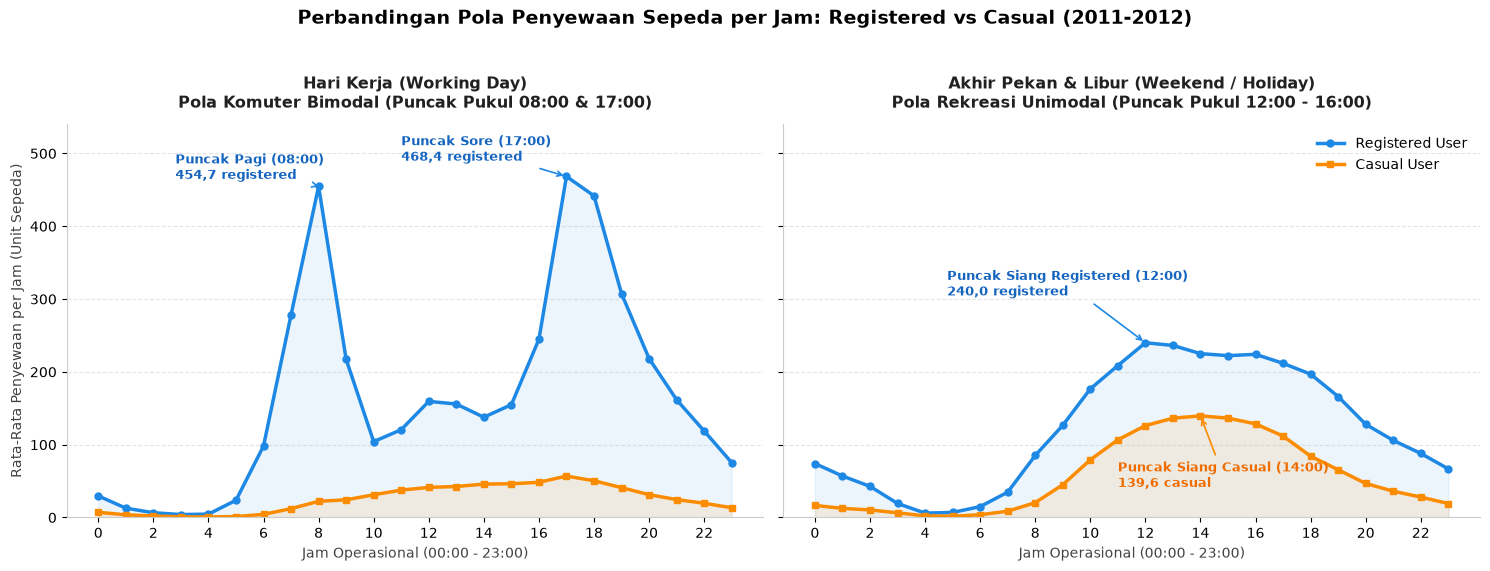

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
day_types = ['Working Day', 'Weekend / Holiday']
titles = [
    'Hari Kerja (Working Day)\nPola Komuter Bimodal (Puncak Pukul 08:00 & 17:00)',
    'Akhir Pekan & Libur (Weekend / Holiday)\nPola Rekreasi Unimodal (Puncak Pukul 12:00 - 16:00)'
]

for ax, dtype, title in zip(axes, day_types, titles):
    sub = hourly_agg[hourly_agg['day_type'] == dtype]
    ax.plot(sub['hr'], sub['registered'], marker='o', linewidth=2.5, markersize=5, color='#1E88E5', label='Registered User')
    ax.plot(sub['hr'], sub['casual'], marker='s', linewidth=2.5, markersize=5, color='#FB8C00', label='Casual User')
    ax.fill_between(sub['hr'], sub['registered'], color='#1E88E5', alpha=0.08)
    ax.fill_between(sub['hr'], sub['casual'], color='#FB8C00', alpha=0.10)

    ax.set_title(title, fontsize=11.5, fontweight='bold', pad=12, color='#212121')
    ax.set_xlabel('Jam Operasional (00:00 - 23:00)', fontsize=10, color='#424242')
    ax.set_xticks(range(0, 24, 2))
    ax.set_ylim(0, 540)
    ax.grid(axis='y', linestyle='--', alpha=0.4, color='#BDBDBD')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

axes[0].annotate('Puncak Pagi (08:00)\n454,7 registered', xy=(8, 454.74), xytext=(2.8, 465),
                 arrowprops=dict(arrowstyle='->', color='#1E88E5', lw=1.2), fontsize=9, fontweight='bold', color='#1565C0')
axes[0].annotate('Puncak Sore (17:00)\n468,4 registered', xy=(17, 468.39), xytext=(11.0, 490),
                 arrowprops=dict(arrowstyle='->', color='#1E88E5', lw=1.2), fontsize=9, fontweight='bold', color='#1565C0')
axes[1].annotate('Puncak Siang Registered (12:00)\n240,0 registered', xy=(12, 240.01), xytext=(4.8, 305),
                 arrowprops=dict(arrowstyle='->', color='#1E88E5', lw=1.2), fontsize=9, fontweight='bold', color='#1565C0')
axes[1].annotate('Puncak Siang Casual (14:00)\n139,6 casual', xy=(14, 139.59), xytext=(11.0, 42),
                 arrowprops=dict(arrowstyle='->', color='#FB8C00', lw=1.2), fontsize=9, fontweight='bold', color='#EF6C00')

axes[0].set_ylabel('Rata-Rata Penyewaan per Jam (Unit Sepeda)', fontsize=10, color='#424242')
axes[1].legend(frameon=False, fontsize=10, loc='upper right')
fig.suptitle('Perbandingan Pola Penyewaan Sepeda per Jam: Registered vs Casual (2011-2012)', fontsize=13.5, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


### Pertanyaan 2:

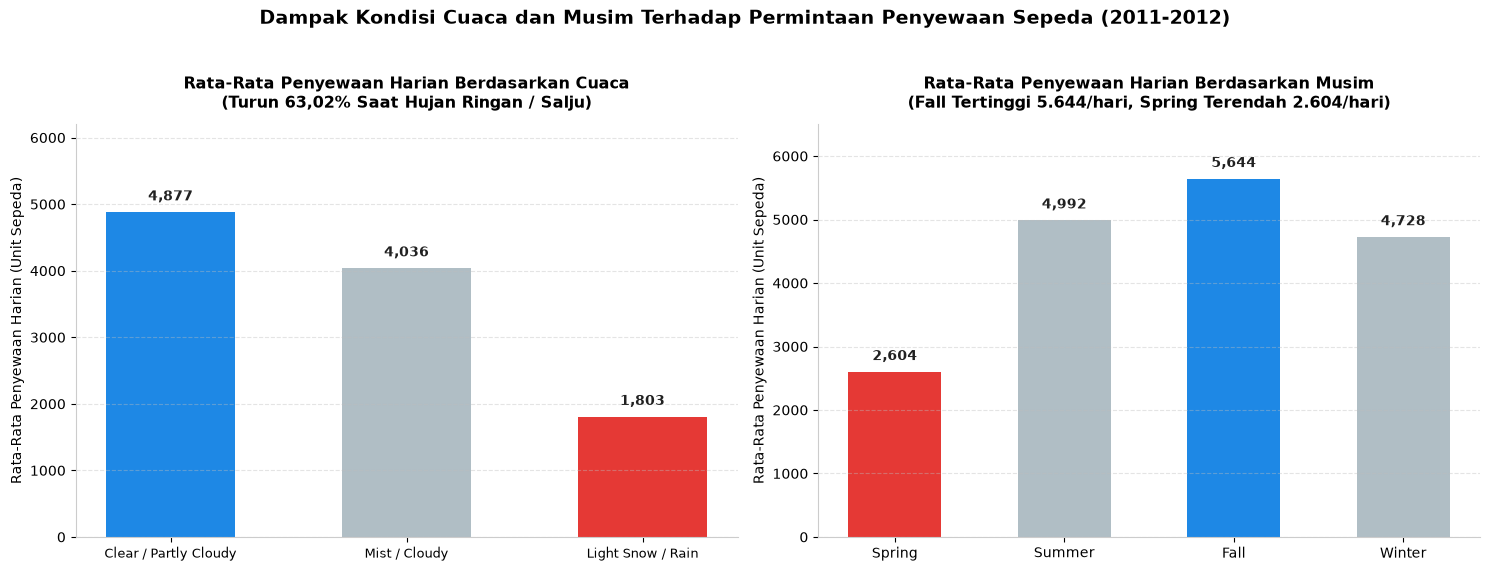

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

weather_order = ['Clear / Partly Cloudy', 'Mist / Cloudy', 'Light Snow / Light Rain']
w_means = day_clean.groupby('weather_label')['cnt'].mean().reindex(weather_order)
w_colors = ['#1E88E5', '#B0BEC5', '#E53935']

bars1 = axes[0].bar(w_means.index, w_means.values, color=w_colors, width=0.55)
axes[0].set_title('Rata-Rata Penyewaan Harian Berdasarkan Cuaca\n(Turun 63,02% Saat Hujan Ringan / Salju)', fontsize=11.5, fontweight='bold', pad=12)
axes[0].set_ylabel('Rata-Rata Penyewaan Harian (Unit Sepeda)', fontsize=10)
axes[0].set_ylim(0, 6200)
axes[0].grid(axis='y', linestyle='--', alpha=0.4, color='#BDBDBD')
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].set_xticks([0, 1, 2])
axes[0].set_xticklabels(['Clear / Partly Cloudy', 'Mist / Cloudy', 'Light Snow / Rain'], rotation=0, ha='center', fontsize=9.5)

for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 130, f'{h:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#212121')

s_means = day_clean.groupby('season_label')['cnt'].mean().reindex(season_order)
s_colors = ['#E53935', '#B0BEC5', '#1E88E5', '#B0BEC5']

bars2 = axes[1].bar(s_means.index, s_means.values, color=s_colors, width=0.55)
axes[1].set_title('Rata-Rata Penyewaan Harian Berdasarkan Musim\n(Fall Tertinggi 5.644/hari, Spring Terendah 2.604/hari)', fontsize=11.5, fontweight='bold', pad=12)
axes[1].set_ylabel('Rata-Rata Penyewaan Harian (Unit Sepeda)', fontsize=10)
axes[1].set_ylim(0, 6500)
axes[1].grid(axis='y', linestyle='--', alpha=0.4, color='#BDBDBD')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].tick_params(axis='x', labelsize=10)

for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 130, f'{h:,.0f}', ha='center', va='bottom', fontsize=10, fontweight='bold', color='#212121')

fig.suptitle('Dampak Kondisi Cuaca dan Musim Terhadap Permintaan Penyewaan Sepeda (2011-2012)', fontsize=13.5, fontweight='bold', y=1.03)
plt.setp(axes[0].get_xticklabels(), rotation=0, ha='center')
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- **Visualisasi 1 (Panel Kiri – Working Day):** Permintaan didominasi secara tajam oleh pengguna *registered* dengan pola **bimodal** pada jam berangkat kerja pukul **08:00** (rata-rata **454,74** *registered*; total **225.552** transaksi) dan jam pulang kerja pukul **17:00–18:00** (rata-rata **468,39** dan **441,78** *registered*), sementara aktivitas pengguna *casual* cenderung landai sepanjang hari kerja.
- **Visualisasi 1 (Panel Kanan – Weekend / Holiday):** Pola berubah menjadi **unimodal** dengan lonjakan bertahap sejak pagi hingga mencapai puncak aktivitas siang–sore pada rentang pukul **12:00–16:00** (puncak *registered* pukul **12:00** sebesar **240,01/jam** dan puncak *casual* pukul **14:00** sebesar **139,59/jam**), mencerminkan penggunaan sepeda untuk rekreasi.
- **Visualisasi 2 (Panel Kiri – Kondisi Cuaca):** Kondisi cuaca buruk (*Light Snow / Light Rain*) memangkas rata-rata permintaan harian sebesar **63,02%** hingga hanya tersisa **36,98%** (1.803 unit/hari) dibandingkan hari cerah (*Clear / Partly Cloudy*, 4.877 unit/hari). *Catatan:* Kategori ke-4 (*Heavy Rain / Snow*) tidak muncul pada diagram batang harian karena di dataset `day.csv` tidak terdapat satu pun hari penuh dengan rata-rata cuaca kategori 4 (kondisi ekstrem ini hanya tercatat pada 3 jam spesifik di `hour.csv` dengan rata-rata 74,33 sewa/jam).
- **Visualisasi 2 (Panel Kanan – Musim):** Permintaan bergerak naik dari titik terendah pada musim **Spring** (**2.604** unit/hari) menuju puncaknya pada musim **Fall** (**5.644** unit/hari, atau meningkat **+116,74%**), sebelum kembali melandai pada musim **Winter** (**4.728** unit/hari).

## Analisis Lanjutan (Opsional)

Rata-Rata Penyewaan per Jam Berdasarkan Blok Waktu Operasional:
day_type                    Weekend / Holiday  Working Day
time_period                                               
1. Night (00-05)                        43.00        16.44
2. Morning Commute (06-09)              85.00       277.91
3. Midday (10-15)                      338.95       179.66
4. Evening Commute (16-19)             297.34       414.75
5. Late Evening (20-23)                129.70       165.78

Distribusi Tingkat Permintaan Harian per Musim (%):
demand_tier   Low Demand (<=3.000)  Medium Demand (3.001-6.000)  High Demand (>6.000)
season_label                                                                         
Spring                       64.64                        32.60                  2.76
Summer                       13.59                        52.72                 33.70
Fall                          2.13                        56.38                 41.49
Winter                       14.61      

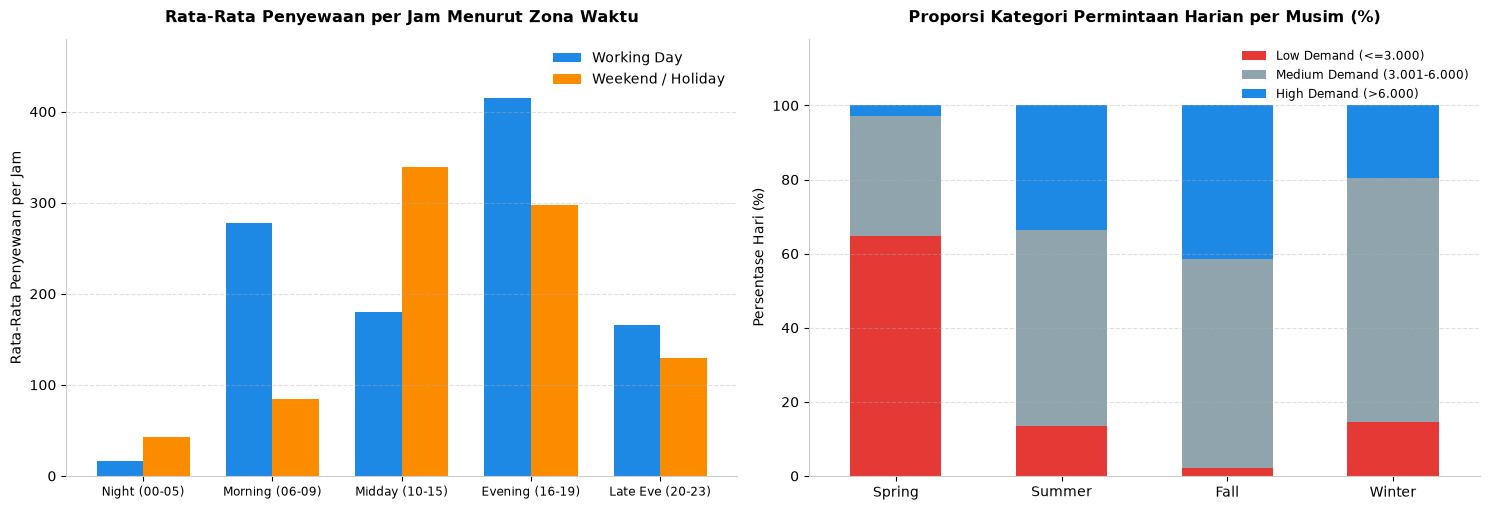

In [23]:
def group_time_period(hr):
    if 0 <= hr <= 5:
        return '1. Night (00-05)'
    elif 6 <= hr <= 9:
        return '2. Morning Commute (06-09)'
    elif 10 <= hr <= 15:
        return '3. Midday (10-15)'
    elif 16 <= hr <= 19:
        return '4. Evening Commute (16-19)'
    else:
        return '5. Late Evening (20-23)'

hour_clean['time_period'] = hour_clean['hr'].apply(group_time_period)

period_pivot = hour_clean.groupby(['time_period', 'day_type'])['cnt'].mean().unstack().round(2)
print('Rata-Rata Penyewaan per Jam Berdasarkan Blok Waktu Operasional:')
print(period_pivot)

day_clean['demand_tier'] = pd.cut(
    day_clean['cnt'],
    bins=[0, 3000, 6000, 10000],
    labels=['Low Demand (<=3.000)', 'Medium Demand (3.001-6.000)', 'High Demand (>6.000)']
)

tier_season_pct = (pd.crosstab(day_clean['season_label'], day_clean['demand_tier'], normalize='index').reindex(season_order) * 100).round(2)
print('\nDistribusi Tingkat Permintaan Harian per Musim (%):')
print(tier_season_pct)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

x = np.arange(len(period_pivot.index))
width = 0.36
axes[0].bar(x - width/2, period_pivot['Working Day'], width, label='Working Day', color='#1E88E5')
axes[0].bar(x + width/2, period_pivot['Weekend / Holiday'], width, label='Weekend / Holiday', color='#FB8C00')
axes[0].set_title('Rata-Rata Penyewaan per Jam Menurut Zona Waktu', fontsize=11.5, fontweight='bold', pad=12)
axes[0].set_xticks(x)
axes[0].tick_params(axis='x', rotation=0)
axes[0].set_xticklabels(['Night (00-05)', 'Morning (06-09)', 'Midday (10-15)', 'Evening (16-19)', 'Late Eve (20-23)'], rotation=0, ha='center', fontsize=8.8)
axes[0].set_ylabel('Rata-Rata Penyewaan per Jam', fontsize=10)
axes[0].set_ylim(0, 480)
axes[0].grid(axis='y', linestyle='--', alpha=0.4)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
axes[0].legend(frameon=False)

tier_colors = ['#E53935', '#90A4AE', '#1E88E5']
tier_season_pct.plot(kind='bar', stacked=True, ax=axes[1], color=tier_colors, width=0.55)
axes[1].set_title('Proporsi Kategori Permintaan Harian per Musim (%)', fontsize=11.5, fontweight='bold', pad=12)
axes[1].set_xlabel('')
axes[1].set_ylabel('Persentase Hari (%)', fontsize=10)
axes[1].set_xticklabels(season_order, rotation=0, fontsize=10)
axes[1].set_ylim(0, 118)
axes[1].grid(axis='y', linestyle='--', alpha=0.4)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)
axes[1].legend(frameon=False, loc='upper right', fontsize=8.8)

plt.setp(axes[0].get_xticklabels(), rotation=0, ha='center')
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- **Zona Waktu Paling Padat:** Pada hari kerja, blok **Evening Commute (16:00–19:59)** mencatat beban tertinggi (**414,75 sewa/jam**), disusul **Morning Commute (06:00–09:59)** sebesar **277,91 sewa/jam**. Pada akhir pekan, pusat kepadatan bergeser ke blok **Midday (10:00–15:59)** dengan rata-rata **338,95 sewa/jam**.
- **Distribusi Kapasitas Musiman:** Sebanyak **41,49%** hari pada musim **Fall** dan **33,70%** pada musim **Summer** masuk kategori *High Demand (> 6.000 sewa/hari)*, sedangkan pada musim **Spring**, **64,64%** harinya berada pada kategori *Low Demand (≤ 3.000 sewa/hari)*.

## Conclusion & Recommendation

## Conclusion

- **Conclusion pertanyaan 1:** Pengguna *registered* mendominasi total penyewaan dengan kontribusi **81,17%** (2.672.662 transaksi), di mana volume pada *Working Day* mencapai **1.989.125 transaksi** (rata-rata **3.978,25/hari**) dibandingkan *Weekend/Holiday* sebesar **683.537 transaksi** (rata-rata **2.959,03/hari**). Pada hari kerja, permintaan membentuk pola komuter dua puncak (*bimodal*), yakni pukul **08:00** (rata-rata **454,74** *registered*; total `cnt` **477,01/jam**) dan jam pulang kerja pukul **17:00–18:00** (rata-rata **468,39** dan **441,78** *registered*; total `cnt` **525,29** dan **492,23/jam**). Sebaliknya, pengguna *casual* berkontribusi **18,83%** (620.017 transaksi) dengan total penyewaan lebih tinggi pada *Weekend/Holiday* sebesar **316.732 transaksi** (rata-rata **1.371,13/hari**) dibandingkan *Working Day* sebesar **303.285 transaksi** (rata-rata **606,57/hari**), atau naik **+126,05%** secara rata-rata harian, dan membentuk puncak tunggal (*unimodal*) pada siang hingga sore hari (**12:00–16:00**, dengan puncak *casual* pukul **14:00** sebesar **139,59/jam** dan puncak total `cnt` pukul **13:00** sebesar **372,73/jam**).
- **Conclusion pertanyaan 2:** Kondisi cuaca dan pergantian musim berkaitan erat dengan perbedaan volume penyewaan harian. Dibandingkan hari cerah (*Clear / Partly Cloudy*, n = 463 hari, rata-rata **4.876,79 sewa/hari**), rata-rata penyewaan turun **17,24%** saat cuaca berkabut/berawan (*Mist / Cloudy*, n = 247 hari, rata-rata **4.035,86 sewa/hari**) dan merosot paling tajam sebesar **63,02%** saat hujan ringan/salju (*Light Snow / Light Rain*, n = 21 hari, rata-rata **1.803,29 sewa/hari**). Secara musiman, **Fall** mencatat rata-rata permintaan harian tertinggi (**5.644,30 sewa/hari** dengan 41,49% hari berkategori *High Demand*), sedangkan **Spring** mencatat rata-rata terendah (**2.604,13 sewa/hari**, lebih rendah 53,86% dibanding Fall dengan 64,64% hari berada pada kategori *Low Demand*).

**Rekomendasi Action Item:**
- **Dynamic Fleet Rebalancing Berbasis Zona Waktu & Tipe Hari:** Pada hari kerja, jadwalkan distribusi ulang (*rebalancing*) dan pengecekan kesiapan unit sepeda sebelum memasuki jam sibuk komuter pagi (sebelum pukul **07:00** untuk mengantisipasi puncak pukul 08:00) dan sore hari (sebelum pukul **16:00** untuk mengantisipasi lonjakan pukul 17:00–18:00). Pada akhir pekan/hari libur, pastikan kapasitas armada tersedia optimal sebelum pukul **12:00** untuk menyerap lonjakan permintaan pada rentang pukul **12:00–16:00**.
- **Kampanye Konversi *Casual* ke *Registered* di Akhir Pekan:** Luncurkan promo paket *Weekend-to-Weekday Pass* atau insentif pendaftaran keanggotaan melalui aplikasi pada rentang pukul **12:00–16:00** di akhir pekan/hari libur, tepat saat rata-rata penyewaan pengguna *casual* berada di level tertinggi (126,25–139,59 sewa/jam).
- **Penjadwalan *Preventive Maintenance* & Efisiensi Operasional:** Alokasikan jadwal perawatan besar armada sepeda dan unit docking pada musim **Spring** (di mana 64,64% hari berada pada kategori *Low Demand* ≤ 3.000 sewa/hari), serta manfaatkan zona waktu **Night (00:00–05:59)** atau hari dengan prakiraan hujan ringan/salju untuk perawatan rutin agar seluruh unit siap beroperasi penuh pada musim puncak **Summer** dan **Fall**.

In [24]:
# Export dataset bersih untuk kebutuhan dashboard Streamlit
import os
os.makedirs('dashboard', exist_ok=True)
hour_clean.to_csv('dashboard/main_data.csv', index=False)
print(f'Dataset bersih berhasil disimpan ke dashboard/main_data.csv ({hour_clean.shape[0]:,} baris, {hour_clean.shape[1]} kolom)')


Dataset bersih berhasil disimpan ke dashboard/main_data.csv (17,379 baris, 28 kolom)
